In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl joblib streamlit


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]



In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import re
import string
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
files = os.listdir()

excel_files = [
    file for file in files
    if file.lower().endswith((".xlsx", ".xls"))
]

print("Excel files found:")
for file in excel_files:
    print(file)

Excel files found:
AI-Powered Chatbot.xlsx


In [4]:
file_name = "AI-Powered Chatbot.xlsx"

df = pd.read_excel(file_name)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Shape: (200, 10)


,Conversation ID,User ID,Timestamp,User Message,Intent,Intent Confidence,Topic,Sentiment Score,Sentiment Label,Bot Response
0,conv_0001,user_0001,2026-09-01T08:05:12,How do I add a course to my schedule?,course_registration,0.92,Registration,0.10,neutral,"To add a course, go to the student portal > Re..."
1,conv_0002,user_0002,2026-09-01T09:12:45,When is the library open on weekends?,campus_facilities,0.88,Facilities,0.35,positive,The library hours are 9:00–18:00 on Saturdays ...
2,conv_0003,user_0003,2026-09-01T09:45:03,I forgot my student portal password.,technical_issue,0.95,IT Support,-0.20,negative,I can help reset your password. Please visit t...
3,conv_0004,user_0004,2026-09-01T10:02:33,Are there scholarships for international stude...,financial_aid,0.90,Financial Aid,0.25,positive,Yes — we have several scholarships for interna...
4,conv_0005,user_0005,2026-09-01T10:15:50,I need to book an appointment with career serv...,career_services,0.89,Career,0.40,positive,You can book an appointment via the Career Ser...


In [5]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Columns:
['Conversation ID', 'User ID', 'Timestamp', 'User Message', 'Intent', 'Intent Confidence', 'Topic', 'Sentiment Score', 'Sentiment Label', 'Bot Response']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Conversation ID    200 non-null    str    
 1   User ID            200 non-null    str    
 2   Timestamp          200 non-null    str    
 3   User Message       200 non-null    str    
 4   Intent             200 non-null    str    
 5   Intent Confidence  200 non-null    float64
 6   Topic              200 non-null    str    
 7   Sentiment Score    200 non-null    float64
 8   Sentiment Label    200 non-null    str    
 9   Bot Response       200 non-null    str    
dtypes: float64(2), str(8)
memory usage: 62.1 KB


In [6]:
print("Missing values:")
display(df.isnull().sum())

Missing values:


Conversation ID      0
User ID              0
Timestamp            0
User Message         0
Intent               0
Intent Confidence    0
Topic                0
Sentiment Score      0
Sentiment Label      0
Bot Response         0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (200, 10)


In [9]:
for col in df.columns:
    if df[col].nunique() <= 50:
        print("\nColumn:", col)
        print(df[col].value_counts().head(20))


Column: Intent
Intent
campus_facilities      23
student_services       20
administration         19
financial_aid          18
student_life           12
course_registration    10
career_services        10
academic_advising      10
academic_policies      10
technical_issue         9
academic_support        8
accessibility           8
housing                 6
course_information      6
safety                  6
research_support        6
mental_health           5
health                  3
study_abroad            2
academic_programs       2
Name: count, dtype: int64

Column: Intent Confidence
Intent Confidence
0.88    20
0.86    18
0.80    18
0.85    17
0.82    15
0.79    13
0.87    11
0.81    11
0.78    11
0.84    10
0.83    10
0.90     9
0.89     7
0.77     6
0.92     5
0.91     5
0.95     4
0.76     4
0.94     2
0.93     2
Name: count, dtype: int64

Column: Sentiment Score
Sentiment Score
 0.10    26
 0.00    22
 0.05    19
-0.05    15
 0.20    14
 0.15    13
 0.45    11
-0.10    11
 0.

In [10]:
text_candidates = []

for col in df.columns:
    if df[col].dtype == "object":
        avg_length = df[col].astype(str).str.len().mean()
        text_candidates.append((col, avg_length))

text_candidates = sorted(
    text_candidates,
    key=lambda x: x[1],
    reverse=True
)

print("Possible text columns:")
for col, avg_length in text_candidates:
    print(col, "Average length:", round(avg_length, 2))

Possible text columns:


In [11]:
# Detect likely label column
label_candidates = []

for col in df.columns:
    if df[col].dtype == "object":
        unique_count = df[col].nunique()

        if unique_count < len(df) * 0.5:
            label_candidates.append((col, unique_count))

print("Possible label columns:")

for col, count in label_candidates:
    print(col, "Unique values:", count)

Possible label columns:


In [12]:
print(df.columns.tolist())

['Conversation ID', 'User ID', 'Timestamp', 'User Message', 'Intent', 'Intent Confidence', 'Topic', 'Sentiment Score', 'Sentiment Label', 'Bot Response']


In [13]:
TEXT_COLUMN = "Question"
LABEL_COLUMN = "Intent"

In [14]:
TEXT_COLUMN = "text"
LABEL_COLUMN = "category"

In [21]:
# Make sure column names are clean and lowercase
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)
TEXT_COLUMN = "user_message"
LABEL_COLUMN = "intent"
RESPONSE_COLUMN = "bot_response"

# Display actual columns
print("Available columns:")
print(df.columns.tolist())

required_columns = [
    TEXT_COLUMN,
    LABEL_COLUMN,
    RESPONSE_COLUMN
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("\nText column:", TEXT_COLUMN)
print("Label column:", LABEL_COLUMN)
print("Response column:", RESPONSE_COLUMN)

print("\nDataset shape:", df.shape)

print("\nSample data:")

display(
    df[
        [
            TEXT_COLUMN,
            LABEL_COLUMN,
            RESPONSE_COLUMN
        ]
    ].head(10)
)

Available columns:
['conversation_id', 'user_id', 'timestamp', 'user_message', 'intent', 'intent_confidence', 'topic', 'sentiment_score', 'sentiment_label', 'bot_response']

Text column: user_message
Label column: intent
Response column: bot_response

Dataset shape: (200, 10)

Sample data:


,user_message,intent,bot_response
0,How do I add a course to my schedule?,course_registration,"To add a course, go to the student portal > Re..."
1,When is the library open on weekends?,campus_facilities,The library hours are 9:00–18:00 on Saturdays ...
2,I forgot my student portal password.,technical_issue,I can help reset your password. Please visit t...
3,Are there scholarships for international stude...,financial_aid,Yes — we have several scholarships for interna...
4,I need to book an appointment with career serv...,career_services,You can book an appointment via the Career Ser...
5,What are the exam dates for CS101?,exam_schedule,Exam dates are posted on the course page. For ...
6,My grades haven't been updated yet.,grades,Grades are uploaded by instructors and can tak...
7,I'm feeling anxious about finals.,mental_health,I'm sorry you're feeling anxious. The counseli...
8,Can I change my major?,academic_advising,Yes — you can request a major change. Visit Ac...
9,How to connect to campus Wi-Fi?,technical_issue,"To connect, choose the 'UniSecure' network and..."


In [22]:

import re
import string

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    
    text = re.sub(r"\S+@\S+", "", text)
    text = re.sub(r"\d+", "", text)

    
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["clean_text"] = df[TEXT_COLUMN].apply(clean_text)

df = df[df["clean_text"].str.strip() != ""].copy()

df = df.dropna(
    subset=[
        "clean_text",
        LABEL_COLUMN,
        RESPONSE_COLUMN
    ]
).reset_index(drop=True)

print("Dataset after cleaning:", df.shape)

display(
    df[
        [
            TEXT_COLUMN,
            "clean_text",
            LABEL_COLUMN
        ]
    ].head(10)
)

Dataset after cleaning: (200, 11)


,user_message,clean_text,intent
0,How do I add a course to my schedule?,how do i add a course to my schedule,course_registration
1,When is the library open on weekends?,when is the library open on weekends,campus_facilities
2,I forgot my student portal password.,i forgot my student portal password,technical_issue
3,Are there scholarships for international stude...,are there scholarships for international students,financial_aid
4,I need to book an appointment with career serv...,i need to book an appointment with career serv...,career_services
5,What are the exam dates for CS101?,what are the exam dates for cs,exam_schedule
6,My grades haven't been updated yet.,my grades havent been updated yet,grades
7,I'm feeling anxious about finals.,im feeling anxious about finals,mental_health
8,Can I change my major?,can i change my major,academic_advising
9,How to connect to campus Wi-Fi?,how to connect to campus wifi,technical_issue


In [23]:
print("Total unique intents:",
      df[LABEL_COLUMN].nunique())

print("\nIntent distribution:")

intent_counts = df[LABEL_COLUMN].value_counts()

display(intent_counts.to_frame("Count"))

Total unique intents: 26

Intent distribution:


,Count
intent,
campus_facilities,23
student_services,20
administration,19
financial_aid,18
student_life,12
course_registration,10
career_services,10
academic_advising,10
academic_policies,10


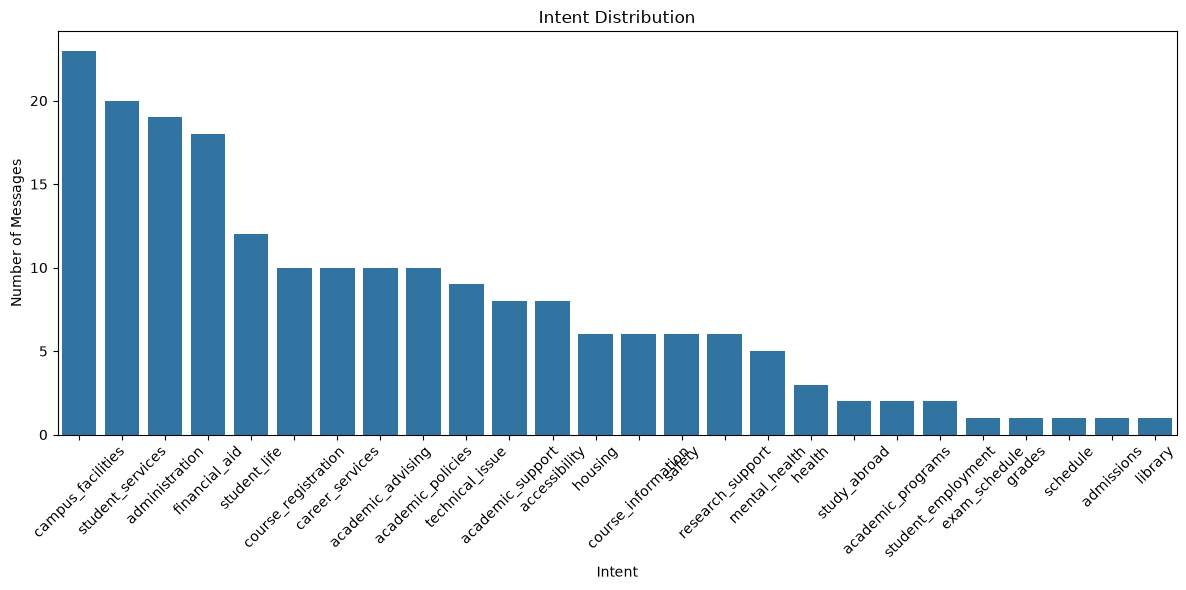

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=intent_counts.index,
    y=intent_counts.values
)

plt.title("Intent Distribution")
plt.xlabel("Intent")
plt.ylabel("Number of Messages")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(
    df[LABEL_COLUMN].astype(str)
)

print("Number of classes:",
      len(label_encoder.classes_))

print("\nIntent Mapping:")

for number, intent in enumerate(
    label_encoder.classes_
):
    print(number, "->", intent)

Number of classes: 26

Intent Mapping:
0 -> academic_advising
1 -> academic_policies
2 -> academic_programs
3 -> academic_support
4 -> accessibility
5 -> administration
6 -> admissions
7 -> campus_facilities
8 -> career_services
9 -> course_information
10 -> course_registration
11 -> exam_schedule
12 -> financial_aid
13 -> grades
14 -> health
15 -> housing
16 -> library
17 -> mental_health
18 -> research_support
19 -> safety
20 -> schedule
21 -> student_employment
22 -> student_life
23 -> student_services
24 -> study_abroad
25 -> technical_issue


In [26]:
X = df["clean_text"]
y = df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200,)
y shape: (200,)


In [27]:
from sklearn.model_selection import train_test_split

class_counts = y.value_counts()

print("Minimum samples in any class:",
      class_counts.min())

if class_counts.min() >= 2:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
    print("Stratified split used.")

else:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    print("Regular split used because some intents have only one sample.")


print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Minimum samples in any class: 1
Regular split used because some intents have only one sample.

Training samples: 160
Testing samples: 40


In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=1
)

X_train_tfidf = vectorizer.fit_transform(
    X_train
)

X_test_tfidf = vectorizer.transform(
    X_test
)

print("Training TF-IDF shape:",
      X_train_tfidf.shape)

print("Testing TF-IDF shape:",
      X_test_tfidf.shape)

print("\nTF-IDF vectorization completed successfully.")

Training TF-IDF shape: (160, 984)
Testing TF-IDF shape: (40, 984)

TF-IDF vectorization completed successfully.


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        random_state=42
    )
}

results = {}
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(
        X_train_tfidf,
        y_train
    )

    predictions = model.predict(
        X_test_tfidf
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    results[name] = accuracy
    trained_models[name] = model

    print(
        "Accuracy:",
        round(accuracy * 100, 2),
        "%"
    )

print("\nAll models trained successfully.")



Training: Logistic Regression
Accuracy: 37.5 %

Training: Naive Bayes
Accuracy: 35.0 %

Training: Linear SVM
Accuracy: 42.5 %

All models trained successfully.


In [30]:
results_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy": list(results.values())
})

results_df["Accuracy (%)"] = (
    results_df["Accuracy"] * 100
)

display(results_df)

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.375,37.5
1,Naive Bayes,0.350,35.0
2,Linear SVM,0.425,42.5


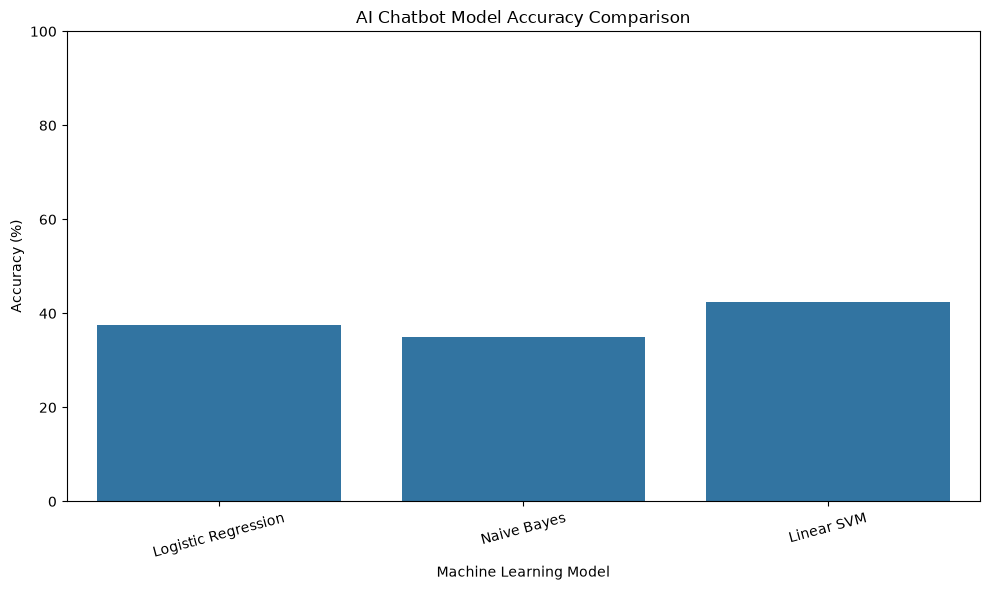

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy (%)"
)

plt.title(
    "AI Chatbot Model Accuracy Comparison"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [32]:
best_model_name = max(
    results,
    key=results.get
)

best_model = trained_models[
    best_model_name
]

best_accuracy = results[
    best_model_name
]

print("Selected Model:")
print(best_model_name)

print(
    "\nAccuracy:",
    round(best_accuracy * 100, 2),
    "%"
)

Selected Model:
Linear SVM

Accuracy: 42.5 %


In [33]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

y_pred = best_model.predict(
    X_test_tfidf
)

print("Classification Report\n")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Classification Report

                     precision    recall  f1-score   support

  academic_advising       0.33      1.00      0.50         1
  academic_policies       0.00      0.00      0.00         3
  academic_programs       0.00      0.00      0.00         0
   academic_support       0.00      0.00      0.00         1
      accessibility       1.00      0.67      0.80         3
     administration       0.40      0.50      0.44         4
         admissions       0.00      0.00      0.00         0
  campus_facilities       0.50      0.71      0.59         7
    career_services       0.00      0.00      0.00         1
 course_information       0.00      0.00      0.00         0
course_registration       0.00      0.00      0.00         1
      exam_schedule       0.00      0.00      0.00         0
      financial_aid       0.67      0.57      0.62         7
             grades       0.00      0.00      0.00         0
             health       0.00      0.00      0.00         1


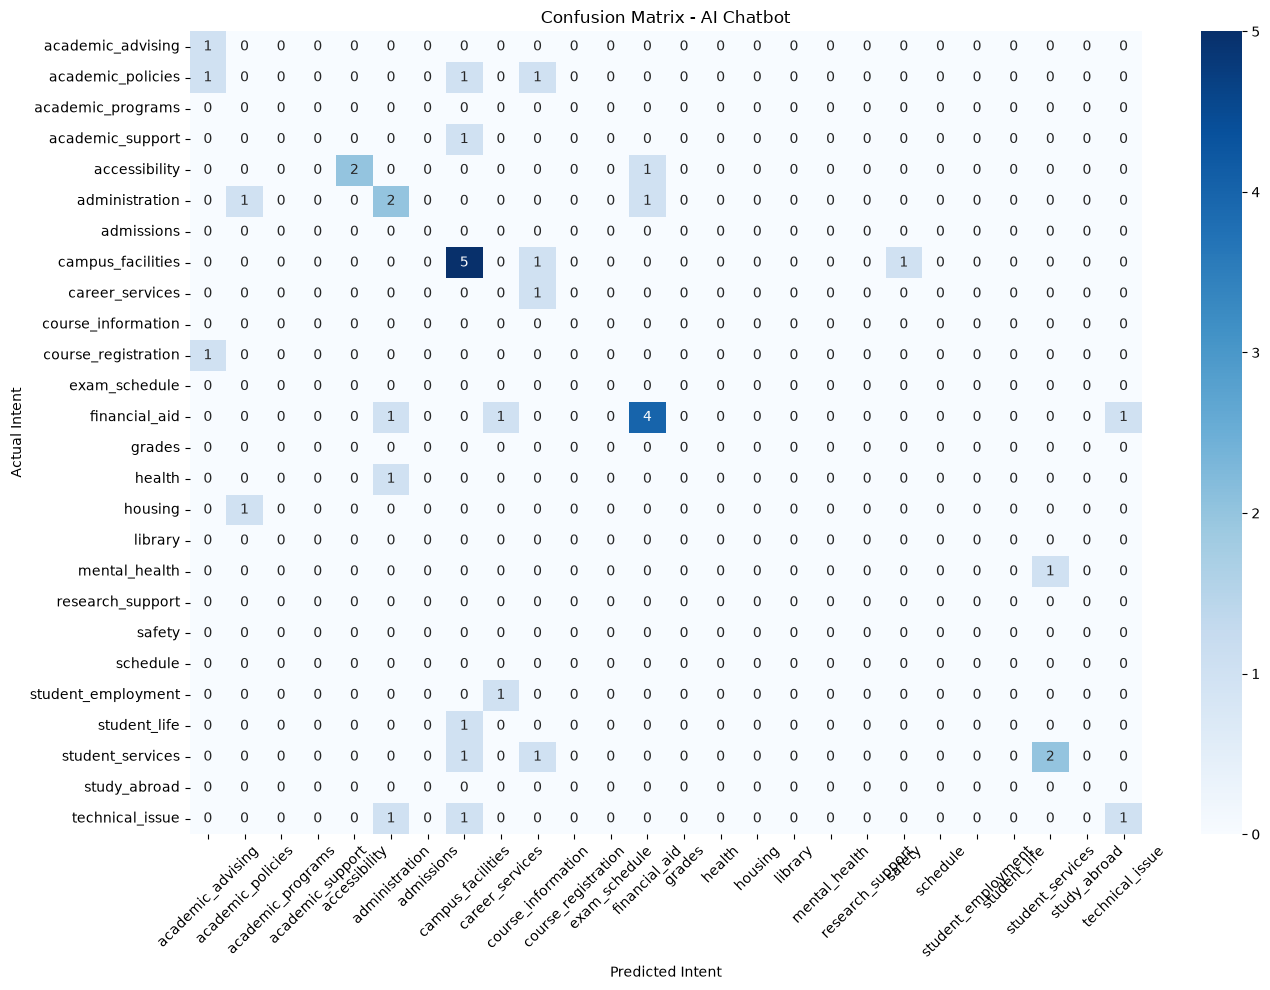

In [34]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(len(label_encoder.classes_)))
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    "Confusion Matrix - AI Chatbot"
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [35]:
response_mapping = {}

for intent in df[LABEL_COLUMN].unique():

    responses = (
        df.loc[
            df[LABEL_COLUMN] == intent,
            RESPONSE_COLUMN
        ]
        .dropna()
        .astype(str)
        .tolist()
    )

    if len(responses) > 0:
        response_mapping[intent] = responses


print(
    "Number of intent response groups:",
    len(response_mapping)
)

print("\nSample responses:")

for intent, responses in list(
    response_mapping.items()
)[:5]:

    print("\nIntent:", intent)
    print("Response:", responses[0])
    

Number of intent response groups: 26

Sample responses:

Intent: course_registration
Response: To add a course, go to the student portal > Registration > Add/Drop Courses and follow the prompts. If you tell me the course code I can check seat availability.

Intent: campus_facilities
Response: The library hours are 9:00–18:00 on Saturdays and 10:00–16:00 on Sundays. Would you like directions or the study room booking link?

Intent: technical_issue
Response: I can help reset your password. Please visit the portal's Password Reset page or confirm you'd like me to send password reset instructions to your registered email.

Intent: financial_aid
Response: Yes — we have several scholarships for international students. Check the Financial Aid page and filter by 'International'. Would you like me to list currently open scholarships?

Intent: career_services
Response: You can book an appointment via the Career Services portal. I can open the booking page or suggest available time slots if you s

In [36]:
import random

def chatbot(user_message):

    if not isinstance(user_message, str):
        return (
            "unknown",
            "Please enter a valid message."
        )

    if not user_message.strip():
        return (
            "unknown",
            "Please enter a message."
        )

    cleaned_message = clean_text(
        user_message
    )

    message_vector = vectorizer.transform(
        [cleaned_message]
    )

    predicted_label = best_model.predict(
        message_vector
    )[0]

    predicted_intent = (
        label_encoder.inverse_transform(
            [predicted_label]
        )[0]
    )

    possible_responses = response_mapping.get(
        predicted_intent,
        []
    )

    if possible_responses:

        response = random.choice(
            possible_responses
        )

    else:

        response = (
            "Sorry, I don't have a response "
            "for that question yet."
        )

    return predicted_intent, response

In [39]:
test_messages = [
    "How do I add a course to my schedule?",
    "When is the library open?",
    "I forgot my student portal password.",
    "What are the exam dates?",
    "How do I connect to WiFi?"
]

for message in test_messages:

    intent, response = chatbot(
        message
    )

    print("User:", message)
    print("Predicted Intent:", intent)
    print("Bot:", response)
    print("-" * 70)
    

User: How do I add a course to my schedule?
Predicted Intent: course_registration
Bot: Swapping lab sections depends on seat availability. Use the Swap option in Registration or request instructor permission; shall I check availability?
----------------------------------------------------------------------
User: When is the library open?
Predicted Intent: campus_facilities
Bot: Printing may require prepaid credits or charges per page. Check the Printing Services page for current rates and payment methods.
----------------------------------------------------------------------
User: I forgot my student portal password.
Predicted Intent: technical_issue
Bot: Use the campus-provided cloud storage or an external drive. I can guide you to set up automatic backups for your documents.
----------------------------------------------------------------------
User: What are the exam dates?
Predicted Intent: exam_schedule
Bot: Exam dates are posted on the course page. For CS101 the midterm is 2026-1

In [40]:
import pickle
import os

# Save trained model
with open("chatbot_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

# Save TF-IDF vectorizer
with open("tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(vectorizer, file)

# Save label encoder
with open("label_encoder.pkl", "wb") as file:
    pickle.dump(label_encoder, file)

# Save response mapping
with open("response_mapping.pkl", "wb") as file:
    pickle.dump(response_mapping, file)

print("All model files saved successfully!")

All model files saved successfully!


In [41]:
required_files = [
    "chatbot_model.pkl",
    "tfidf_vectorizer.pkl",
    "label_encoder.pkl",
    "response_mapping.pkl"
]

print("Checking files...\n")

all_files_exist = True

for file in required_files:

    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗", file, "NOT FOUND")
        all_files_exist = False

print()

if all_files_exist:
    print("SUCCESS: All model files are ready.")
else:
    print("ERROR: One or more files are missing.")

Checking files...

✓ chatbot_model.pkl
✓ tfidf_vectorizer.pkl
✓ label_encoder.pkl
✓ response_mapping.pkl

SUCCESS: All model files are ready.


In [42]:
with open("chatbot_model.pkl", "rb") as file:
    test_model = pickle.load(file)

with open("tfidf_vectorizer.pkl", "rb") as file:
    test_vectorizer = pickle.load(file)

with open("label_encoder.pkl", "rb") as file:
    test_encoder = pickle.load(file)

with open("response_mapping.pkl", "rb") as file:
    test_responses = pickle.load(file)

print("Model loaded successfully.")
print("Vectorizer loaded successfully.")
print("Label encoder loaded successfully.")
print("Response mapping loaded successfully.")

Model loaded successfully.
Vectorizer loaded successfully.
Label encoder loaded successfully.
Response mapping loaded successfully.


In [43]:
def saved_chatbot(user_message):

    cleaned = clean_text(user_message)

    vector = test_vectorizer.transform(
        [cleaned]
    )

    predicted_label = test_model.predict(
        vector
    )[0]

    predicted_intent = test_encoder.inverse_transform(
        [predicted_label]
    )[0]

    responses = test_responses.get(
        predicted_intent,
        []
    )

    if responses:
        response = responses[0]
    else:
        response = "Sorry, I don't have an answer for that."

    return predicted_intent, response

In [44]:
test_question = "How do I register for a course?"

intent, response = saved_chatbot(
    test_question
)

print("User:", test_question)
print("Intent:", intent)
print("Bot:", response)

User: How do I register for a course?
Intent: course_registration
Bot: To add a course, go to the student portal > Registration > Add/Drop Courses and follow the prompts. If you tell me the course code I can check seat availability.


In [45]:
streamlit_code = r'''
import streamlit as st
import pickle
import re
import string
import random


# ==========================================
# PAGE CONFIG
# ==========================================

st.set_page_config(
    page_title="AI-Powered Chatbot",
    page_icon="🤖",
    layout="centered"
)


# ==========================================
# LOAD MODEL FILES
# ==========================================

with open("chatbot_model.pkl", "rb") as file:
    model = pickle.load(file)

with open("tfidf_vectorizer.pkl", "rb") as file:
    vectorizer = pickle.load(file)

with open("label_encoder.pkl", "rb") as file:
    label_encoder = pickle.load(file)

with open("response_mapping.pkl", "rb") as file:
    response_mapping = pickle.load(file)


# ==========================================
# TEXT CLEANING
# ==========================================

def clean_text(text):

    text = str(text).lower()

    text = re.sub(
        r"http\S+|www\S+|https\S+",
        "",
        text
    )

    text = re.sub(
        r"\S+@\S+",
        "",
        text
    )

    text = re.sub(
        r"\d+",
        "",
        text
    )

    text = text.translate(
        str.maketrans(
            "",
            "",
            string.punctuation
        )
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ==========================================
# CHATBOT
# ==========================================

def chatbot(user_message):

    cleaned = clean_text(user_message)

    vector = vectorizer.transform(
        [cleaned]
    )

    predicted_label = model.predict(
        vector
    )[0]

    predicted_intent = label_encoder.inverse_transform(
        [predicted_label]
    )[0]

    responses = response_mapping.get(
        predicted_intent,
        []
    )

    if responses:
        response = random.choice(responses)
    else:
        response = (
            "Sorry, I don't have an answer "
            "for that question."
        )

    return predicted_intent, response


# ==========================================
# CUSTOM CSS
# ==========================================

st.markdown("""
<style>

.title {
    text-align: center;
    font-size: 38px;
    font-weight: bold;
    margin-bottom: 5px;
}

.subtitle {
    text-align: center;
    color: gray;
    margin-bottom: 25px;
}

</style>
""", unsafe_allow_html=True)


# ==========================================
# HEADER
# ==========================================

st.markdown(
    '<div class="title">🤖 AI-Powered Chatbot</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">College Support Assistant</div>',
    unsafe_allow_html=True
)


# ==========================================
# SESSION STATE
# ==========================================

if "messages" not in st.session_state:
    st.session_state.messages = []


# ==========================================
# CHAT HISTORY
# ==========================================

for message in st.session_state.messages:

    with st.chat_message(
        message["role"]
    ):

        st.write(
            message["content"]
        )


# ==========================================
# USER INPUT
# ==========================================

user_input = st.chat_input(
    "Ask your question..."
)


if user_input:

    # User message

    st.session_state.messages.append({
        "role": "user",
        "content": user_input
    })

    with st.chat_message("user"):
        st.write(user_input)


    # Bot response

    intent, response = chatbot(
        user_input
    )

    st.session_state.messages.append({
        "role": "assistant",
        "content": response
    })

    with st.chat_message("assistant"):
        st.write(response)


# ==========================================
# SIDEBAR
# ==========================================

with st.sidebar:

    st.header("🤖 Chatbot")

    st.write(
        "AI-powered college support assistant."
    )

    st.divider()

    st.subheader("Features")

    st.write("✓ NLP")
    st.write("✓ TF-IDF")
    st.write("✓ Intent Classification")
    st.write("✓ Machine Learning")
    st.write("✓ Automated Responses")

    st.divider()

    if st.button("Clear Chat"):

        st.session_state.messages = []

        st.rerun()
'''


with open(
    "app.py",
    "w",
    encoding="utf-8"
) as file:

    file.write(streamlit_code)


print("app.py created successfully!")

app.py created successfully!


In [46]:
if os.path.exists("app.py"):

    print("✓ app.py exists")

    print(
        "File size:",
        os.path.getsize("app.py"),
        "bytes"
    )

else:

    print("✗ app.py was not created")

✓ app.py exists
File size: 4548 bytes


In [47]:
print("PROJECT FILES")
print("=" * 50)

for file in os.listdir():

    if file.endswith(
        (
            ".ipynb",
            ".xlsx",
            ".txt",
            ".pkl",
            ".py"
        )
    ):
        print("✓", file)

PROJECT FILES
✓ AI-Powered Chatbot.txt
✓ AI-Powered Chatbot.xlsx
✓ AiPoweredChatbot.ipynb
✓ app.py
✓ chatbot_model.pkl
✓ label_encoder.pkl
✓ response_mapping.pkl
✓ tfidf_vectorizer.pkl
